C-MAPSS stands for Commercial Modular Aero-Propulsion System Simulation

In [1]:
# Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# data import

# adding "r" allows us to read the file path as raw string

train_path = r"D:\AI_Lab\Projects\NASA_C_MAPSS_RLU_prediction\data\train_FD001.txt"
test_path = r"D:\AI_Lab\Projects\NASA_C_MAPSS_RLU_prediction\data\test_FD001.txt"
rul_path = r"D:\AI_Lab\Projects\NASA_C_MAPSS_RLU_prediction\data\RUL_FD001.txt"

In [3]:
# Adding columns names and sensor numbers w.r.t the table 2 from paper
column_names = ['unit_number', 'time_cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3'] + [f's{i}' for i in range(1, 22)]

df = pd.read_csv('data/train_FD001.txt', sep=' ', header=None)
df = df.iloc[:, :26]   # keep only the first 26 real columns, drop the 2 empties
df.columns = column_names
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   unit_number   20631 non-null  int64  
 1   time_cycle    20631 non-null  int64  
 2   op_setting_1  20631 non-null  float64
 3   op_setting_2  20631 non-null  float64
 4   op_setting_3  20631 non-null  float64
 5   s1            20631 non-null  float64
 6   s2            20631 non-null  float64
 7   s3            20631 non-null  float64
 8   s4            20631 non-null  float64
 9   s5            20631 non-null  float64
 10  s6            20631 non-null  float64
 11  s7            20631 non-null  float64
 12  s8            20631 non-null  float64
 13  s9            20631 non-null  float64
 14  s10           20631 non-null  float64
 15  s11           20631 non-null  float64
 16  s12           20631 non-null  float64
 17  s13           20631 non-null  float64
 18  s14           20631 non-nu

In [4]:
# Checking the max cycle of engine 1

df.loc[df['unit_number'] == 1]

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
187,1,188,-0.0067,0.0003,100.0,518.67,643.75,1602.38,1422.78,14.62,...,519.79,2388.23,8117.69,8.5207,0.03,396,2388,100.0,38.51,22.9588
188,1,189,-0.0006,0.0002,100.0,518.67,644.18,1596.17,1428.01,14.62,...,519.58,2388.33,8117.51,8.5183,0.03,395,2388,100.0,38.48,23.1127
189,1,190,-0.0027,0.0001,100.0,518.67,643.64,1599.22,1425.95,14.62,...,520.04,2388.35,8112.58,8.5223,0.03,398,2388,100.0,38.49,23.0675
190,1,191,-0.0000,-0.0004,100.0,518.67,643.34,1602.36,1425.77,14.62,...,519.57,2388.30,8114.61,8.5174,0.03,394,2388,100.0,38.45,23.1295


# Data pre-processing and EDA
----

In [5]:
# getting the cycle number (max cycle) where that unit failed

df['max_cycle'] = df.groupby('unit_number')['time_cycle'].transform('max')

df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,max_cycle
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,192
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,192
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,192
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,192
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,192


In [6]:
# Calculating the RUL by subtracting the max_cycle with current cycle

df['RUL'] = df['max_cycle'] - df['time_cycle']
df.tail()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s14,s15,s16,s17,s18,s19,s20,s21,max_cycle,RUL
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735,200,4
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594,200,3
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333,200,2
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640,200,1
20630,100,200,-0.0032,-0.0005,100.0,518.67,643.85,1600.38,1432.14,14.62,...,8137.33,8.5036,0.03,396,2388,100.0,38.37,23.0522,200,0


In [7]:
# Extracting the engine 1 data

engine1 = df.loc[df['unit_number'] == 1]
engine1.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s14,s15,s16,s17,s18,s19,s20,s21,max_cycle,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,192,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,192,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,192,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,192,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,192,187


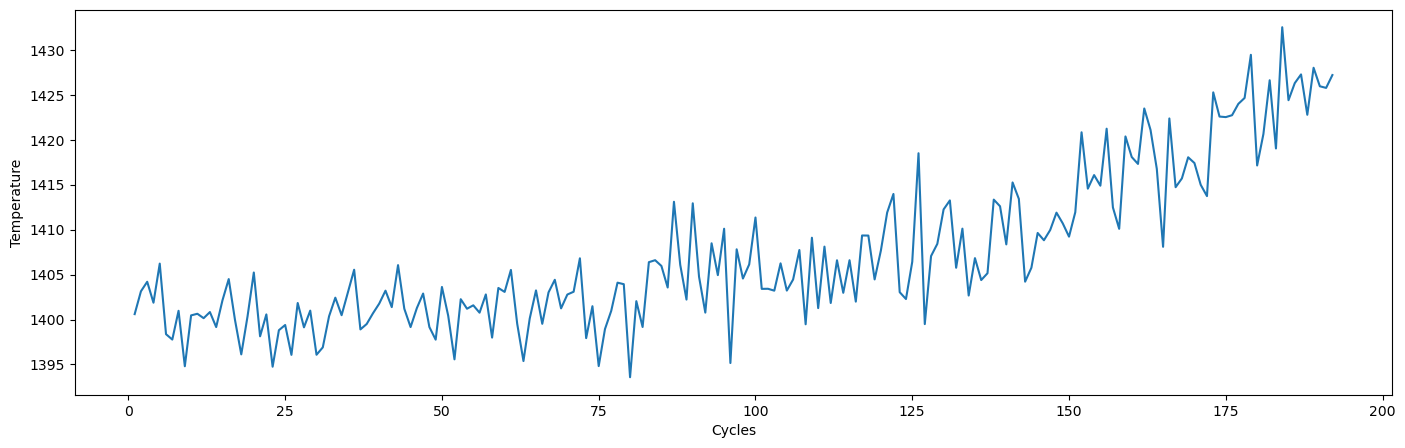

In [8]:
#Plotting the engine 1, sensor data.

fig, ax = plt.subplots(figsize = (17,5))
ax.plot(engine1['time_cycle'], engine1['s4'])

ax.set_xlabel('Cycles')
ax.set_ylabel('Temperature')

plt.show()

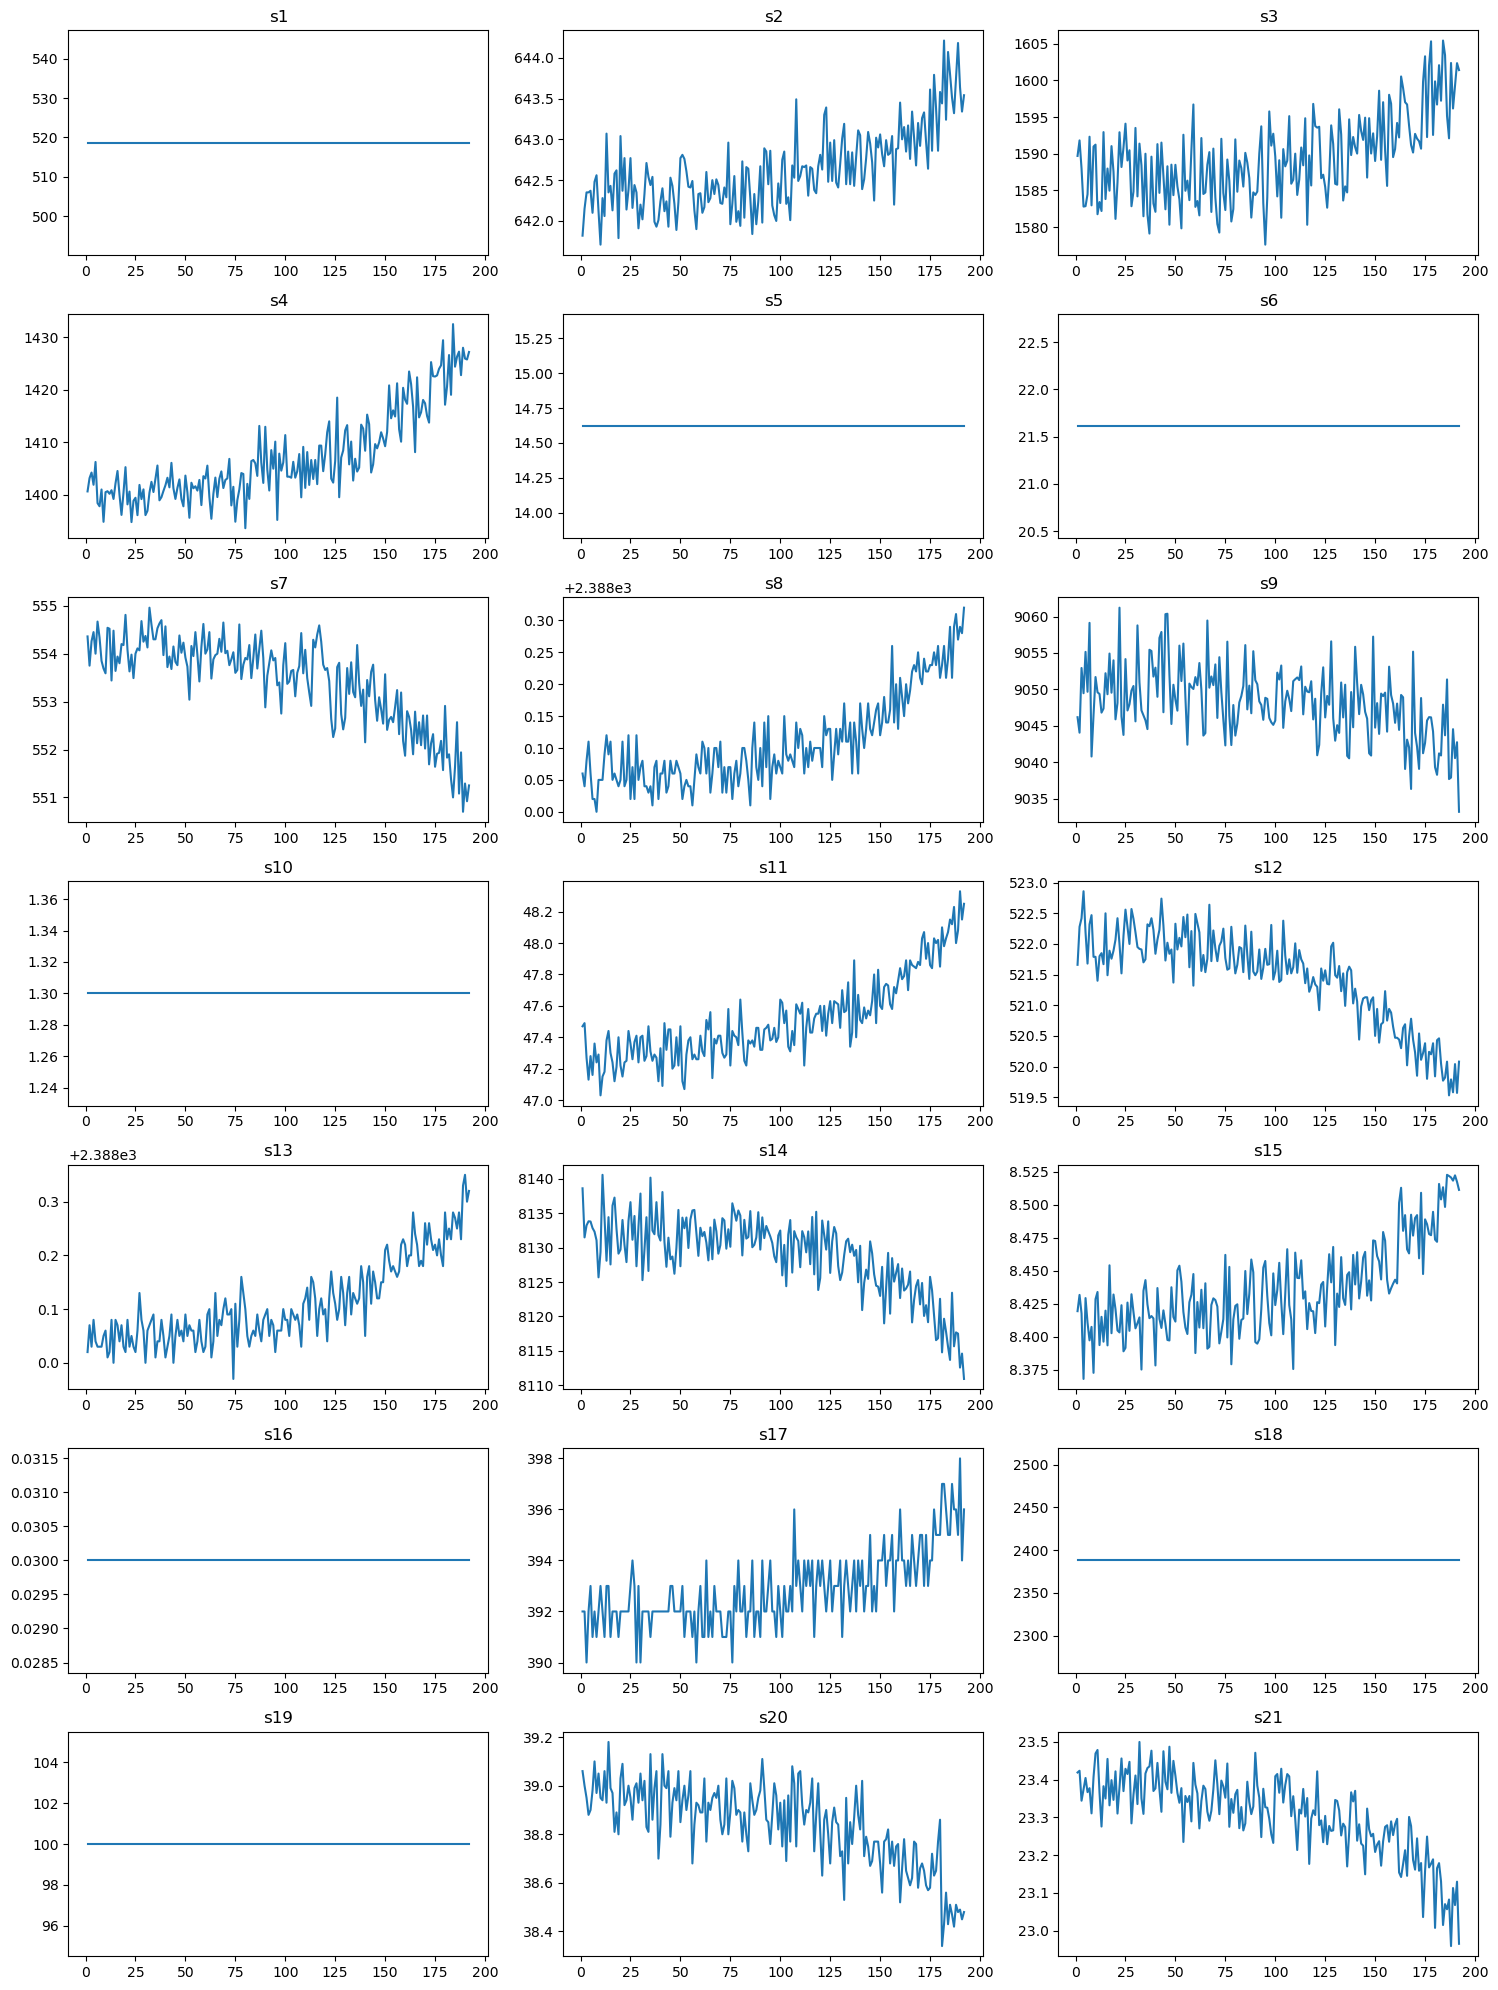

In [9]:
sensor_cols = [f's{i}' for i in range(1, 22)]  # s1 to s21


fig, ax = plt.subplots(7, 3, figsize=(15, 20))  # 7 rows x 3 cols = 21 slots
ax = ax.flatten()  # turns the 2D grid into a flat list so you can index it 0-20

for i, sensor in enumerate(sensor_cols):
    ax[i].plot(engine1['time_cycle'], engine1[sensor])
    ax[i].set_title(sensor)

plt.tight_layout()  # prevents subplot titles/labels from overlapping
plt.show()

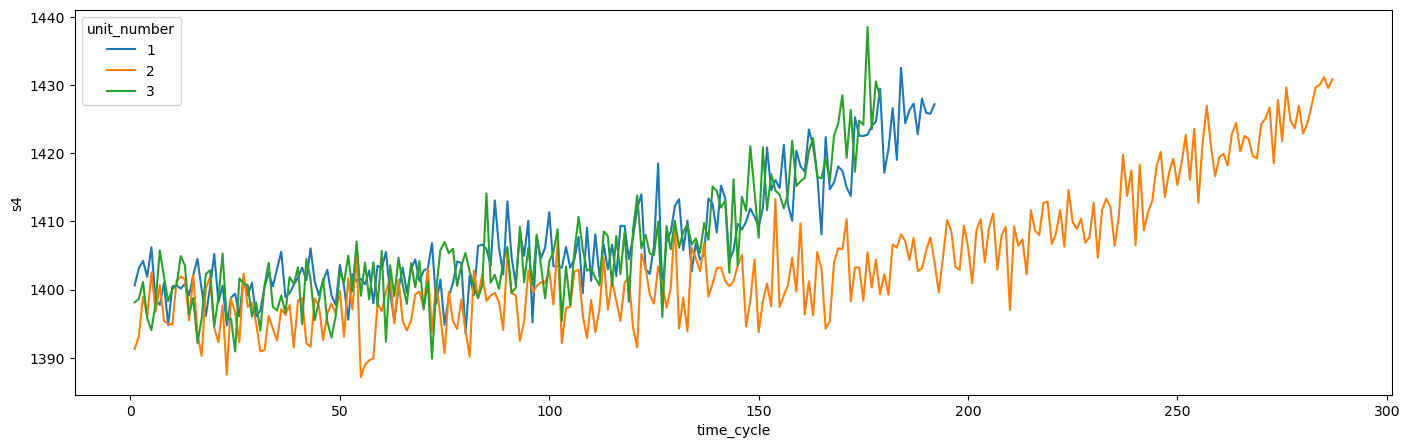

In [ ]:
# Plotting s4 of set engines
engines_set = np.arange(1,4)

filtered_df = df[df['unit_number'].isin(engines_set)].copy() # adding .copy() to avoid slicing warning
filtered_df['unit_number'] = filtered_df['unit_number'].astype(str) # Changing the dtype to str as sns consider this value as continuous variable

plt.figure(figsize=(17,5))
sns.lineplot(filtered_df, x='time_cycle', y='s4', hue='unit_number')

plt.show()

In [11]:
drop_columns = ['s1', 's5', 's6', 's10', 's16', 's18', 's19']
df = df.drop(columns= drop_columns)


In [12]:
df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,...,s11,s12,s13,s14,s15,s17,s20,s21,max_cycle,RUL
0,1,1,-0.0007,-0.0004,100.0,641.82,1589.70,1400.60,554.36,2388.06,...,47.47,521.66,2388.02,8138.62,8.4195,392,39.06,23.4190,192,191
1,1,2,0.0019,-0.0003,100.0,642.15,1591.82,1403.14,553.75,2388.04,...,47.49,522.28,2388.07,8131.49,8.4318,392,39.00,23.4236,192,190
2,1,3,-0.0043,0.0003,100.0,642.35,1587.99,1404.20,554.26,2388.08,...,47.27,522.42,2388.03,8133.23,8.4178,390,38.95,23.3442,192,189
3,1,4,0.0007,0.0000,100.0,642.35,1582.79,1401.87,554.45,2388.11,...,47.13,522.86,2388.08,8133.83,8.3682,392,38.88,23.3739,192,188
4,1,5,-0.0019,-0.0002,100.0,642.37,1582.85,1406.22,554.00,2388.06,...,47.28,522.19,2388.04,8133.80,8.4294,393,38.90,23.4044,192,187


In [ ]:
# checking shape and columns

print(df.shape)
print(df.columns.tolist())

(20631, 21)
['unit_number', 'time_cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 's2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21', 'max_cycle', 'RUL']


In [14]:
df[['op_setting_1','op_setting_2','op_setting_3']].describe()

,op_setting_1,op_setting_2,op_setting_3
count,20631.000000,20631.000000,20631.0
mean,-0.000009,0.000002,100.0
std,0.002187,0.000293,0.0
min,-0.008700,-0.000600,100.0
25%,-0.001500,-0.000200,100.0
50%,0.000000,0.000000,100.0
75%,0.001500,0.000300,100.0
max,0.008700,0.000600,100.0


In [15]:
# check point to save the df

raw_df = df.copy()


In [16]:
# Retrieving the df checkpoint from rew df.

#df = raw_df.copy()

In [ ]:
# Train/Val split

from sklearn.model_selection import train_test_split

engine_IDs = df['unit_number'].unique()
#engine_IDs

train_engine_IDs, val_engine_IDs = train_test_split(engine_IDs, test_size= 0.2, random_state= 42)
#print(train_engine_IDs, val_engine_IDs)

train_df = df[df['unit_number'].isin(train_engine_IDs)].copy()
#print(train_df['unit_number'].unique())
val_df = df[df['unit_number'].isin(val_engine_IDs)].copy()
#print(val_df['unit_number'].unique())


In [ ]:
# Using only sensor columns for scaling

exclude_sensor = ['unit_number', 'time_cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'max_cycle', 'RUL']

train_sensor_df = train_df.drop(columns = exclude_sensor).copy()
val_sensor_df = val_df.drop(columns = exclude_sensor).copy()

In [19]:
train_sensor_df.describe()

,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21
count,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000,16561.000000
mean,642.677606,1590.489097,1408.879098,553.373052,2388.096259,9065.399182,47.539671,521.417076,2388.095864,8143.908227,8.442025,393.205362,38.817927,23.290476
std,0.498124,6.085409,8.965616,0.877772,0.070647,22.659801,0.265733,0.734990,0.071709,19.587082,0.037508,1.546317,0.179872,0.107405
min,641.210000,1571.040000,1385.190000,549.850000,2387.900000,9021.730000,46.850000,518.690000,2387.880000,8099.940000,8.327900,388.000000,38.140000,22.894200
25%,642.330000,1586.280000,1402.380000,552.820000,2388.050000,9053.140000,47.350000,520.960000,2388.040000,8133.500000,8.414900,392.000000,38.700000,23.223600
50%,642.640000,1590.040000,1407.900000,553.450000,2388.090000,9060.910000,47.510000,521.490000,2388.090000,8140.790000,8.438700,393.000000,38.830000,23.299400
75%,642.990000,1594.310000,1414.420000,554.000000,2388.140000,9069.390000,47.700000,521.950000,2388.140000,8148.280000,8.465100,394.000000,38.950000,23.366800
max,644.530000,1616.910000,1441.490000,556.060000,2388.560000,9244.590000,48.520000,523.380000,2388.560000,8293.720000,8.584800,400.000000,39.430000,23.618400


# Scaling
----

In [20]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [21]:
# Scaling the train df sensor columns

'''
We are assigning the scaled sensor columns back to the train df by passing the .columns of train_sensor_df
'''
train_df[train_sensor_df.columns] = scaler.fit_transform(train_sensor_df) 
train_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,...,s11,s12,s13,s14,s15,s17,s20,s21,max_cycle,RUL
192,2,1,-0.0018,0.0006,100.0,-1.581191,-1.092662,-1.963014,1.318090,-1.221017,...,-2.294365,1.242127,-0.500147,-0.315944,-1.373754,-1.426246,0.678684,1.564436,287,286
193,2,2,0.0043,-0.0003,100.0,-1.721722,-0.565155,-1.756664,1.591518,-1.645675,...,-1.127747,1.745551,-1.615806,-0.654442,-0.675217,-0.779529,1.345844,1.098895,287,285
194,2,3,0.0018,0.0003,100.0,-2.263772,-0.356453,-1.106382,2.013053,-0.796358,...,-1.203012,1.582278,-1.476349,-0.169925,-1.648369,-1.426246,1.623827,1.252524,287,284
195,2,4,0.0035,-0.0004,100.0,-2.002785,-1.041719,-1.427619,0.999091,-1.645675,...,-1.654606,1.459824,-2.313093,-0.177072,-1.072476,-1.426246,1.735021,1.975974,287,283
196,2,5,0.0005,0.0004,100.0,-1.902406,-1.883102,-0.709298,1.990267,-0.937911,...,-1.090114,1.160491,-2.173636,-0.369552,-1.475068,-2.072963,2.013004,1.237627,287,282


In [22]:
# Scaling the val df sensor columns

'''
We are assigning the scaled sensor columns back to the train df by passing the .columns of train_sensor_df
'''
val_df[val_sensor_df.columns] = scaler.transform(val_sensor_df) 
val_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,...,s11,s12,s13,s14,s15,s17,s20,s21,max_cycle,RUL
0,1,1,-0.0007,-0.0004,100.0,-1.721722,-0.129674,-0.923456,1.124412,-0.513252,...,-0.262191,0.330523,-1.057977,-0.269994,-0.600564,-0.779529,1.345844,1.196659,192,191
1,1,2,0.0019,-0.0003,100.0,-1.059217,0.218711,-0.640143,0.429450,-0.796358,...,-0.186926,1.174097,-0.360690,-0.634020,-0.272625,-0.779529,1.012264,1.239489,192,190
2,1,3,-0.0043,0.0003,100.0,-0.657699,-0.410683,-0.521909,1.010484,-0.230146,...,-1.014848,1.364582,-0.918519,-0.545183,-0.645889,-2.072963,0.734281,0.500210,192,189
3,1,4,0.0007,0.0000,100.0,-0.657699,-1.265212,-0.781799,1.226948,0.194512,...,-1.541708,1.963247,-0.221232,-0.514550,-1.968310,-0.779529,0.345105,0.776741,192,188
4,1,5,-0.0019,-0.0002,100.0,-0.617547,-1.255352,-0.296597,0.714270,-0.513252,...,-0.977215,1.051643,-0.779062,-0.516082,-0.336613,-0.132811,0.456298,1.060721,192,187


In [23]:
# clipping the RUL as till 125 cycles, the engine is not shown signs of degrading based on NASA/PHM08 challenge scoring (2008 paper by Frank Heimes)

train_df['RUL'] = train_df['RUL'].clip(upper = 125)
val_df['RUL'] = val_df['RUL'].clip(upper = 125)

In [24]:
train_df[train_sensor_df.columns].describe().loc[['mean', 'std']]


,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21
mean,-2.197573e-14,2.314788e-14,-4.397719e-15,-4.517681e-14,-1.117486e-12,-6.902907e-14,-3.026918e-14,1.055058e-13,9.343313e-13,3.926198e-15,5.130101e-15,-1.643846e-14,7.115424e-14,2.569813e-14
std,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00,1.000030e+00


In [25]:
val_df[val_sensor_df.columns].describe().loc[['mean', 'std']]

,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21
mean,0.033865,0.028340,0.030918,-0.030845,0.028196,-0.034953,0.028562,-0.024872,0.020403,-0.040245,0.016251,0.017348,-0.046681,-0.036393
std,1.019181,1.037386,1.019407,1.041376,1.023892,0.862803,1.025404,1.017466,1.014766,0.859039,0.999633,1.008026,1.023694,1.038941


# Linear Regression
----

In [26]:
X_train = train_df.drop(columns= exclude_sensor)
y_train = train_df['RUL']

X_val = val_df.drop(columns= exclude_sensor)
y_val = val_df['RUL']

In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error

In [28]:
LR_model = LinearRegression()

In [29]:
LR_model.fit(X_train, y_train)

LinearRegression()

In [30]:
y_pred = LR_model.predict(X_val)

In [ ]:
rmse = root_mean_squared_error(y_val, y_pred)
print(f"RMSE: {rmse}")

# Got RMSE as 20.4 i.e the model predection off by 20 cycles

RMSE: 20.42818797258912


In [32]:
# Checking with dumb model i.e. average RUL for every row

dumb_rmse = root_mean_squared_error(y_val, np.full_like(y_val, y_train.mean()))
print(f"Dumb baseline RMSE: {dumb_rmse}")

Dumb baseline RMSE: 41.7167528612603


# Random Forest
----

In [33]:
from sklearn.ensemble import RandomForestRegressor

RF_model = RandomForestRegressor()

In [34]:
RF_model.fit(X_train, y_train)

RandomForestRegressor()

In [35]:
RF_y_pred = RF_model.predict(X_val)

In [36]:
rmse_RF = root_mean_squared_error(y_val, RF_y_pred)
print(f"RMSE for RandomForest: {rmse_RF}")

RMSE for RandomForest: 17.25973405377034


# Validation against the test data
----
#### Here we will be loading the test data and RUL data file and performing the data cleaning and preprocessing.

In [37]:
raw_test_df = pd.read_csv('data/test_FD001.txt', sep= ' ', header= None)
raw_test_df = raw_test_df.iloc[:, :26]
raw_test_df.columns = column_names
raw_test_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13096 entries, 0 to 13095
Data columns (total 26 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   unit_number   13096 non-null  int64  
 1   time_cycle    13096 non-null  int64  
 2   op_setting_1  13096 non-null  float64
 3   op_setting_2  13096 non-null  float64
 4   op_setting_3  13096 non-null  float64
 5   s1            13096 non-null  float64
 6   s2            13096 non-null  float64
 7   s3            13096 non-null  float64
 8   s4            13096 non-null  float64
 9   s5            13096 non-null  float64
 10  s6            13096 non-null  float64
 11  s7            13096 non-null  float64
 12  s8            13096 non-null  float64
 13  s9            13096 non-null  float64
 14  s10           13096 non-null  float64
 15  s11           13096 non-null  float64
 16  s12           13096 non-null  float64
 17  s13           13096 non-null  float64
 18  s14           13096 non-nu

In [ ]:
# Extracting max cycle for each engine i.e. the cut-off cycle

raw_test_df['max_cycle'] = raw_test_df.groupby(['unit_number'])['time_cycle'].transform('max')


In [39]:
test_df = raw_test_df[raw_test_df['time_cycle'] == raw_test_df['max_cycle']]
test_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,max_cycle
30,1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,...,2388.06,8130.11,8.4024,0.03,393,2388,100.0,38.81,23.3552,31
79,2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,...,2388.09,8126.90,8.4505,0.03,391,2388,100.0,38.81,23.2618,49
205,3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,...,2388.14,8131.46,8.4119,0.03,395,2388,100.0,38.93,23.2740,126
311,4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,...,2388.11,8133.64,8.4634,0.03,395,2388,100.0,38.58,23.2581,106
409,5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,...,2388.15,8125.74,8.4362,0.03,394,2388,100.0,38.75,23.4117,98


In [40]:
test_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,max_cycle
30,1,31,-0.0006,0.0004,100.0,518.67,642.58,1581.22,1398.91,14.62,...,2388.06,8130.11,8.4024,0.03,393,2388,100.0,38.81,23.3552,31
79,2,49,0.0018,-0.0001,100.0,518.67,642.55,1586.59,1410.83,14.62,...,2388.09,8126.90,8.4505,0.03,391,2388,100.0,38.81,23.2618,49
205,3,126,-0.0016,0.0004,100.0,518.67,642.88,1589.75,1418.89,14.62,...,2388.14,8131.46,8.4119,0.03,395,2388,100.0,38.93,23.2740,126
311,4,106,0.0012,0.0004,100.0,518.67,642.78,1594.53,1406.88,14.62,...,2388.11,8133.64,8.4634,0.03,395,2388,100.0,38.58,23.2581,106
409,5,98,-0.0013,-0.0004,100.0,518.67,642.27,1589.94,1419.36,14.62,...,2388.15,8125.74,8.4362,0.03,394,2388,100.0,38.75,23.4117,98


In [ ]:
# Loading the true RUL data

rul_true = pd.read_csv('data/RUL_FD001.txt',header= None, names= ['RUL'])
rul_true.head()

,RUL
0,112
1,98
2,69
3,82
4,91


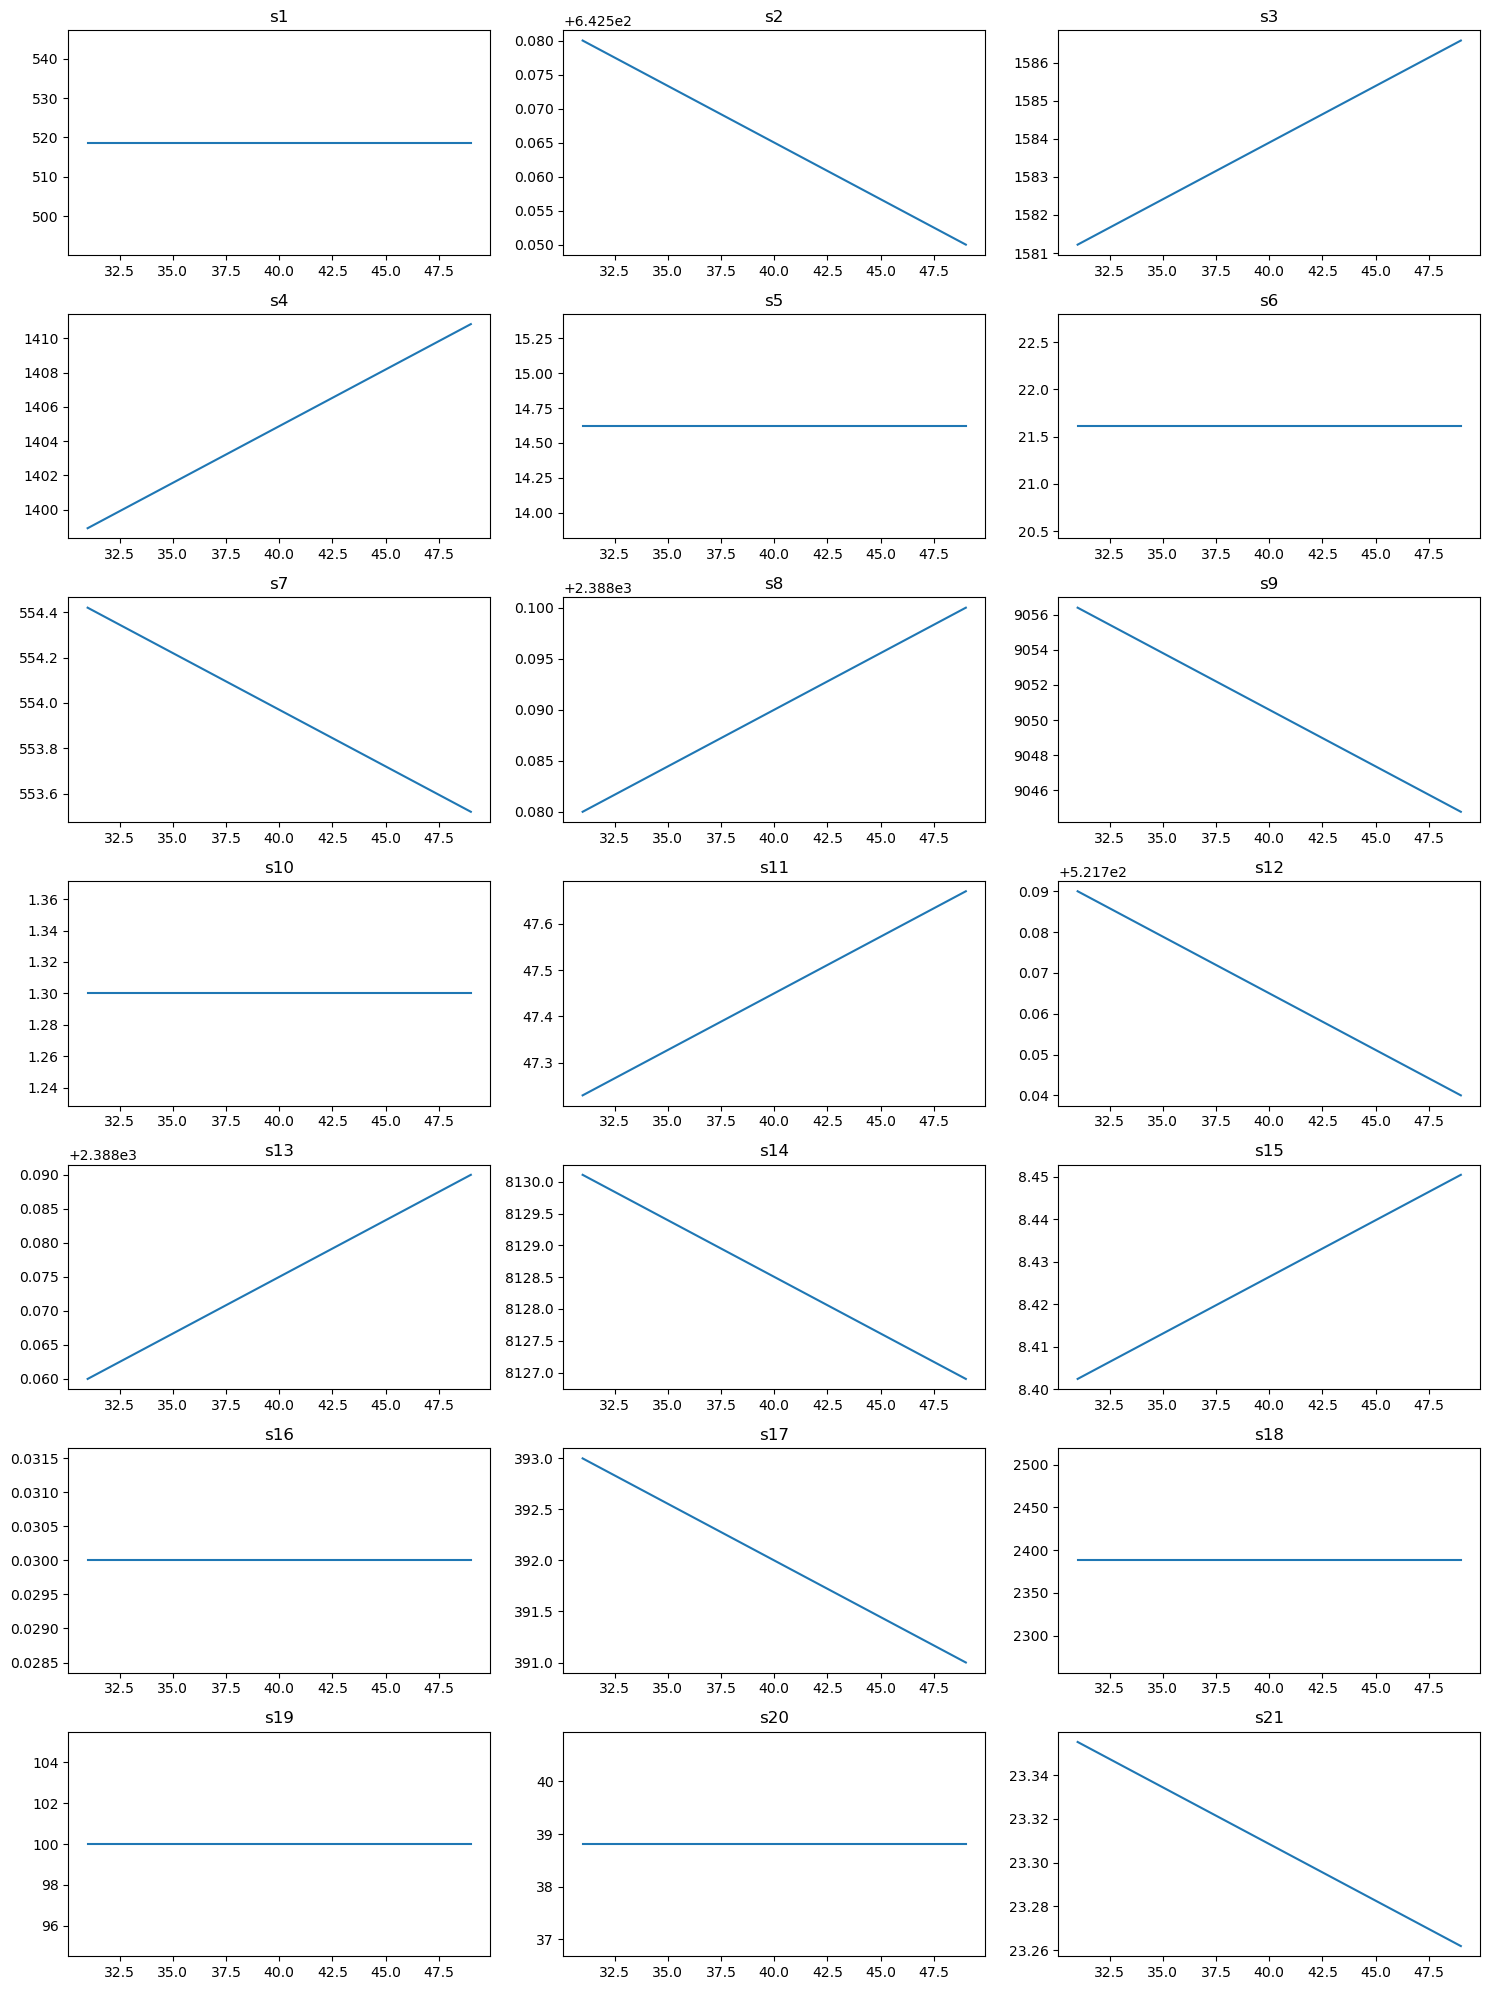

In [ ]:
# Plotting graphs for sensor data

test_engine1 = test_df.loc[df['unit_number'] == 1]

fig, ax = plt.subplots(7, 3, figsize=(15, 20))  # 7 rows x 3 cols = 21 slots
ax = ax.flatten()  # turns the 2D grid into a flat list so you can index it 0-20


for i, sensor in enumerate(sensor_cols):
    ax[i].plot(test_engine1['time_cycle'], test_engine1[sensor])
    ax[i].set_title(sensor)

plt.tight_layout()  # prevents subplot titles/labels from overlapping
plt.show()

In [43]:
test_df['unit_number'].values

array([  1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,
        14,  15,  16,  17,  18,  19,  20,  21,  22,  23,  24,  25,  26,
        27,  28,  29,  30,  31,  32,  33,  34,  35,  36,  37,  38,  39,
        40,  41,  42,  43,  44,  45,  46,  47,  48,  49,  50,  51,  52,
        53,  54,  55,  56,  57,  58,  59,  60,  61,  62,  63,  64,  65,
        66,  67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,
        79,  80,  81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,
        92,  93,  94,  95,  96,  97,  98,  99, 100], dtype=int64)

In [44]:
test_df = test_df.drop(columns= drop_columns)
test_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21,max_cycle
30,1,31,-0.0006,0.0004,100.0,642.58,1581.22,1398.91,554.42,2388.08,9056.40,47.23,521.79,2388.06,8130.11,8.4024,393,38.81,23.3552,31
79,2,49,0.0018,-0.0001,100.0,642.55,1586.59,1410.83,553.52,2388.10,9044.77,47.67,521.74,2388.09,8126.90,8.4505,391,38.81,23.2618,49
205,3,126,-0.0016,0.0004,100.0,642.88,1589.75,1418.89,552.59,2388.16,9049.26,47.88,520.83,2388.14,8131.46,8.4119,395,38.93,23.2740,126
311,4,106,0.0012,0.0004,100.0,642.78,1594.53,1406.88,552.64,2388.13,9051.30,47.65,521.88,2388.11,8133.64,8.4634,395,38.58,23.2581,106
409,5,98,-0.0013,-0.0004,100.0,642.27,1589.94,1419.36,553.29,2388.10,9053.99,47.46,521.00,2388.15,8125.74,8.4362,394,38.75,23.4117,98


In [45]:
backup_df = test_df.copy()

In [46]:
# Restoring backup
#test_df = backup_df.copy()

In [ ]:
# extracting only test sensor data

test_exclude_sensor = ['unit_number', 'time_cycle', 'op_setting_1', 'op_setting_2', 'op_setting_3', 'max_cycle']

test_sensor_df = test_df.drop(columns=test_exclude_sensor)

In [ ]:
# Transforming the sensor data

test_df[test_sensor_df.columns] = scaler.transform(test_sensor_df)
test_df.head()

,unit_number,time_cycle,op_setting_1,op_setting_2,op_setting_3,s2,s3,s4,s7,s8,s9,s11,s12,s13,s14,s15,s17,s20,s21,max_cycle
30,1,31,-0.0006,0.0004,100.0,-0.195953,-1.523214,-1.111959,1.192769,-0.230146,-0.397155,-1.165379,0.507401,-0.500147,-0.704477,-1.056479,-0.132811,-0.044072,0.602629,31
79,2,49,0.0018,-0.0001,100.0,-0.256180,-0.640748,0.217605,0.167415,0.052959,-0.910414,0.490465,0.439371,-0.081775,-0.868365,0.225949,-1.426246,-0.044072,-0.267001,49
205,3,126,-0.0016,0.0004,100.0,0.406325,-0.121458,1.116622,-0.892118,0.902277,-0.712260,1.280755,-0.798778,0.615512,-0.635552,-0.803193,1.160624,0.623088,-0.153409,126
311,4,106,0.0012,0.0004,100.0,0.205566,0.664051,-0.222981,-0.835154,0.477618,-0.622230,0.415200,0.629856,0.197140,-0.524250,0.569885,1.160624,-1.322794,-0.301451,106
409,5,98,-0.0013,-0.0004,100.0,-0.818306,-0.090235,1.169046,-0.094620,0.052959,-0.503514,-0.299824,-0.567475,0.754970,-0.927590,-0.155313,0.513906,-0.377652,1.128690,98


In [53]:
# model prediction

X_test = test_df.drop(columns= test_exclude_sensor)

# Linear Regression
y_pred_test_LR = LR_model.predict(X_test)

# Random Forest
y_pred_test_RF = RF_model.predict(X_test)

In [54]:
# Clipping rul_true to 125 cycles to match the training set as the model trained till 125 cycles.

y_test_clipped = rul_true['RUL'].clip(upper = 125)


In [55]:
# Computing RMSE between Predict LR and RF model and clipped true RUL

# LR model
rmse_test_LR = root_mean_squared_error(y_test_clipped, y_pred_test_LR)
print("LR RMSE: ", rmse_test_LR)

# RF model
rmse_test_RF = root_mean_squared_error(y_test_clipped, y_pred_test_RF)
print("RF RMSE: ", rmse_test_RF)

LR RMSE:  20.77636286577184
RF RMSE:  16.799808332239984
